# Python

In [3]:
import numpy as np
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os

## Visualizing polymers in a 3D lattice

#### Importing full lattice state

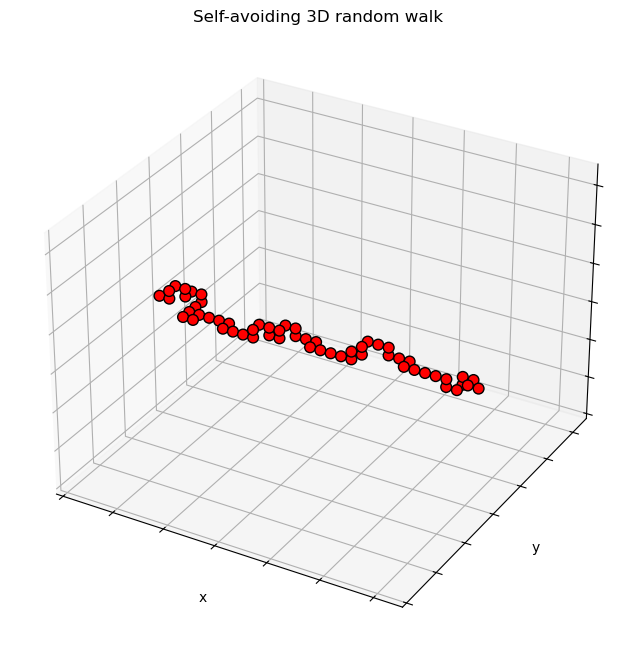

In [20]:
# import json data
dirname = "20251024/testpoly_frame10" 
# dirname = "20250924/testpoly" 
lattice = json.load(open("data/"+dirname+".json"))
lattice = np.array(lattice)

# Get coordinates where array == 1
coords1 = np.argwhere(lattice[..., -1] == 1)
coords2 = np.argwhere(lattice[..., -2] == 1)
x1, y1, z1 = coords1[:, 2], coords1[:, 1], coords1[:, 0]
x2, y2, z2 = coords2[:, 2], coords2[:, 1], coords2[:, 0]

# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
# ax.scatter(x1, y1, z1, s=40, c='blue', marker='o', alpha=0.5)
ax.scatter(x2, y2, z2, s=60, c='red', marker='o', edgecolor="black", alpha=1)

# ax.scatter(4,7,8, s=80, c='black', marker='o', alpha=1)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')
plt.show()

#### Importing species coordinates

In [178]:
dirname = "20251208/test_frame1"
labels, project =False, False
adjust_pos, elev, azim = False, 0, 90  # default is 30, 120
# colors = ["C0", "C0", "C3", "C2", "C0", "C3", "C0"]
colors = {"a":"C0", "b":"C0", "c":"C1", 
          "d":"C0", "e":"C0", "f":"C1", "g":"C2"}

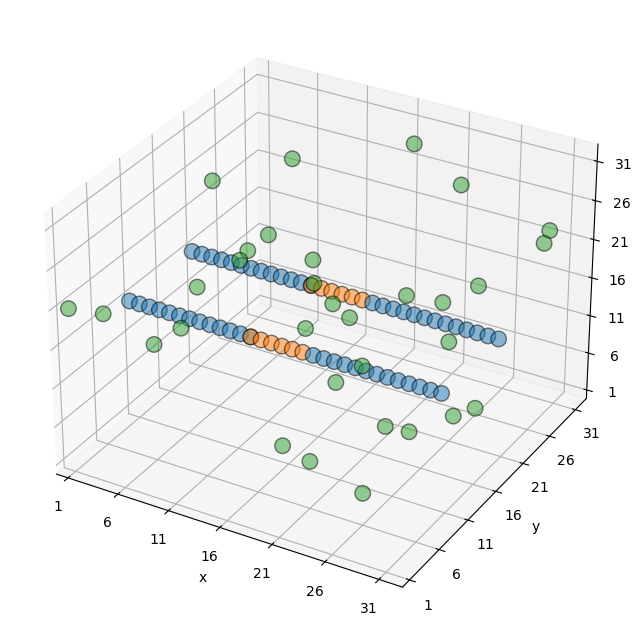

In [179]:
# import json data

slist = json.load(open("data/"+dirname+".json"))
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
L = int(slist["1"]["boxlength"])
S = 4000
i = 0
for key, val in slist.items():
    arr = np.array(val["coords"])
    l = None

    if len(arr) == 4:
        x, y, z, l = arr
    else:
        x, y, z = arr
    
    # if val["name"][:4] == "poly":
    #     ax.scatter(x-0.5, y-0.5, z-0.5, s=60, c='red', 
    #                marker='o', edgecolor="black", alpha=1)

    sp_name = val["name"][-1]

    ax.scatter(x-0.5, y-0.5, z-0.5, s=S/L, color = colors[sp_name], 
                marker='o', edgecolor="black", alpha=0.5)
        
    if project:
        # projections
        ax.scatter(x-0.45, y-0.55, 0, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(x-0.45, L, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(0, y-0.55, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        
        
    if l is not None and labels:
        for k in range(len(x)):
            ax.text(x[k]-0.5, y[k]-0.5, z[k]-0.5, l[k], size=10)

    i += 1

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, slist["1"]["boxlength"])
ax.set_ylim(0, slist["1"]["boxlength"])
ax.set_zlim(0, slist["1"]["boxlength"])

# Generalized ticks based on lattice size
# Use boxlength as lattice size (integer number of sites per axis)
ticks = np.arange(0.5, L + 0.5, step=min(L, int(L/8)+1))
labels = np.arange(1, L + 1, step=min(L, int(L/8)+1))

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_yticks(ticks)
ax.set_yticklabels(labels)
ax.set_zticks(ticks)
ax.set_zticklabels(labels)
ax.grid(True, which="both")

if adjust_pos:
    ax.view_init(elev=elev, azim=azim)
plt.show()

In [180]:
out_dir = "media/figures/20251218"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "prewetting_enhancers_setup.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20251218/prewetting_enhancers_setup.pdf


#### Density maps

In [210]:
def densityMap(dlat, pos, ax=None, max_radius=None, xbounds=None):
    """
    Compute 2D polar density map (y-z cross section) around a line parallel to x-axis.
    Averages density over all x positions.
    
    Parameters
    ----------
    dlat : ndarray
        3D density lattice of shape (L, L, L)
    pos : tuple or list
        (y, z) coordinates of the line's position
    max_radius : float, optional
        Maximum radius to consider. Defaults to L/2.
        
    Returns
    -------
    yz_density : ndarray
        2D array of shape (2*max_radius+1, 2*max_radius+1) with mean densities
        centered on the line position
    extent : tuple
        (y_min, y_max, z_min, z_max) for plotting
    """
    L = dlat.shape[0]
    y0, z0 = pos
    
    if max_radius is None:
        max_radius = L // 2

    if xbounds is None:
        xbounds = [0,L-1]

    if ax is None:
        ax = [2,1,0]
    
    # Create 2D density map centered on (y0, z0)
    size = 2 * max_radius + 1
    yz_density = np.zeros((size, size))
    counts = np.zeros((size, size))
    
    for x in range(xbounds[0], xbounds[1]):
        for dy in range(-max_radius, max_radius + 1):
            for dz in range(-max_radius, max_radius + 1):
                # Get actual y, z with periodic boundaries
                y = (y0 + dy) % L
                z = (z0 + dz) % L

                xyz = [x,y,z]
                
                # Map to output array indices
                iy = dy + max_radius
                iz = dz + max_radius
                
                yz_density[iz, iy] += dlat[xyz[ax[0]], xyz[ax[1]], xyz[ax[2]]]
                counts[iz, iy] += 1
    
    # Average over all x positions
    yz_density = np.divide(yz_density, counts, where=counts > 0)
    
    extent = (-max_radius - 0.5, max_radius + 0.5, -max_radius - 0.5, max_radius + 0.5)
    
    return yz_density, extent


def plotAxialDensity(data, line_pos=None, width=3, 
                     max_radius=None, xbounds=None, ybounds=None, 
                     show=True, key="density_lattice"):
    """
    Plot axial density and polar cross-section from simulation data.
    
    Parameters
    ----------
    data : dict
        Simulation results dictionary with 'density_lattice' key
    line_pos : tuple, optional
        (y, z) position of the line. Defaults to center of box.
    width : float
        Width around line to pool densities for axial plot
    max_radius : int, optional
        Maximum radius for polar cross-section. Defaults to L/2.
    """
    if key not in data:
        print("No 'density_lattice' found in data.")
        return None
    
    dlat = np.array(data[key])
    L = dlat.shape[0]
    
    if line_pos is None:
        line_pos = (L // 2, L // 2)
    
    if max_radius is None:
        max_radius = L // 2
    
    # Compute axial density
    xz_density, extent = densityMap(dlat, line_pos, max_radius=max_radius, 
                                         xbounds=xbounds)
    
    # Compute polar density map
    yz_density, extent = densityMap(dlat, line_pos, ax=[2,0,1], max_radius=max_radius, 
                                         xbounds=ybounds)
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    # Polar cross-section (y-z plane)
    im = axes[0].imshow(xz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    axes[0].set_xlabel('Δy from axis')
    axes[0].set_ylabel('Δz from axis')
    axes[0].set_title('Cross-section density (avg over x)')
    
    # Polar cross-section (y-z plane)
    im = axes[1].imshow(yz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    axes[1].set_xlabel('Δx from axis')
    axes[1].set_ylabel('Δz from axis')
    axes[1].set_title('Cross-section density (avg over y)')

    
    # Colorbar
    cbar = plt.colorbar(im, ax=axes[1])
    cbar.set_label('Mean density')
    
    plt.tight_layout()
    plt.show()
    
    return xz_density, yz_density

In [207]:
def get_data(dirname, keya=16, keyb=1):

    res_or_path = 'data/{}/output_cpu{}.json'.format(dirname, keya)

    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            return res_[str(keya)][str(keyb)]
        
    return None

# data = get_data("20251210/filament_prewetting_32_124-1024")
data = get_data("20251210/prewet_enhancers_32_1-16")

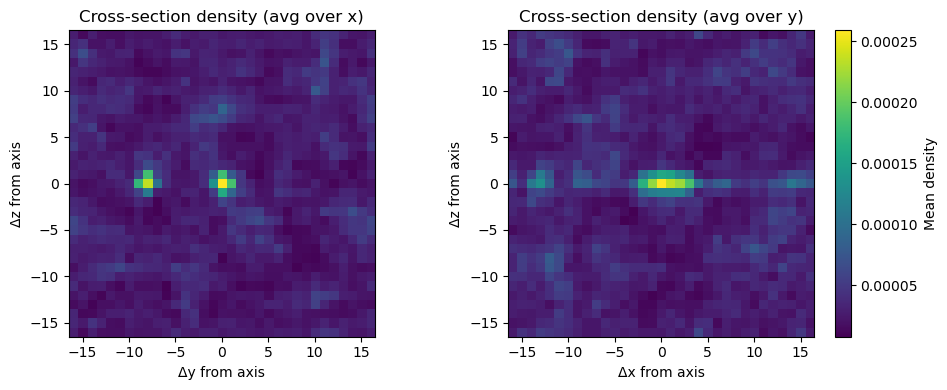

(array([[2.77981900e-05, 1.37782333e-05, 2.90068069e-05, ...,
         2.24802754e-05, 2.19968286e-05, 2.77981900e-05],
        [3.52916151e-05, 2.58644028e-05, 4.59274443e-05, ...,
         2.61061262e-05, 2.75564666e-05, 3.52916151e-05],
        [3.40829981e-05, 1.20861696e-05, 1.32947865e-05, ...,
         1.64371906e-05, 2.36888923e-05, 3.40829981e-05],
        ...,
        [4.37519338e-05, 6.96163366e-05, 4.30267636e-05, ...,
         2.53809561e-05, 2.27219988e-05, 4.37519338e-05],
        [3.57750619e-05, 4.42353806e-05, 1.98213181e-05, ...,
         1.66789140e-05, 2.73147432e-05, 3.57750619e-05],
        [2.77981900e-05, 1.37782333e-05, 2.90068069e-05, ...,
         2.24802754e-05, 2.19968286e-05, 2.77981900e-05]]),
 array([[2.56226795e-05, 4.35102104e-05, 3.55333385e-05, ...,
         3.38412748e-05, 4.85864016e-05, 2.56226795e-05],
        [2.00630415e-05, 2.22385520e-05, 2.48975093e-05, ...,
         3.23909344e-05, 3.38412748e-05, 2.00630415e-05],
        [2.82816368e-05, 

In [208]:
plotAxialDensity(data, [15,15], max_radius=16, 
                          xbounds=[6,16], ybounds=[6,16])

## 20251210

### Filament prewetting

In [169]:
dirname = "20251208/test_frame1"
labels, project = False, False
adjust_pos, elev, azim = False, 0, 90  # default is 30, 120
colors = ["C2", "C2", "C0", "C3", "C0"]

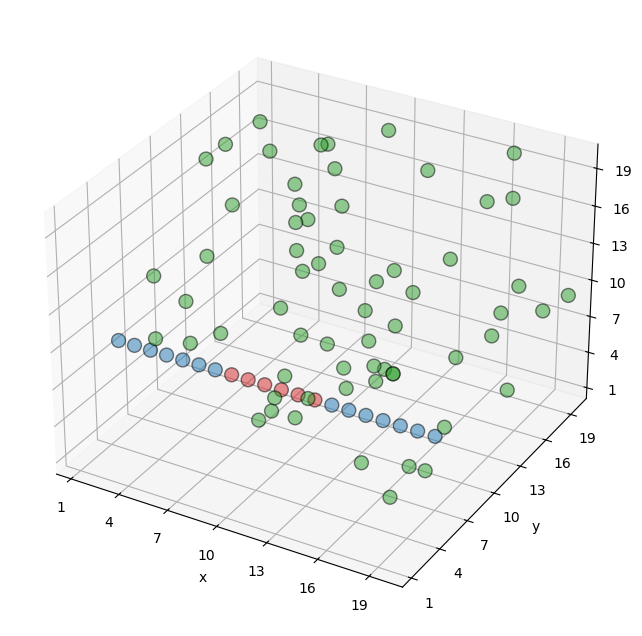

In [170]:
# import json data

slist = json.load(open("data/"+dirname+".json"))
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
L = int(slist["1"]["boxlength"])
S = 2000
i = 0
for key, val in slist.items():
    arr = np.array(val["coords"])
    l = None

    if len(arr) == 4:
        x, y, z, l = arr
    else:
        x, y, z = arr
    
    # if val["name"][:4] == "poly":
    #     ax.scatter(x-0.5, y-0.5, z-0.5, s=60, c='red', 
    #                marker='o', edgecolor="black", alpha=1)

    ax.scatter(x-0.5, y-0.5, z-0.5, s=S/L, color = colors[i], 
                marker='o', edgecolor="black", alpha=0.5)
        
    if project:
        # projections
        ax.scatter(x-0.45, y-0.55, 0, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(x-0.45, L, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(0, y-0.55, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        
        
    if l is not None and labels:
        for k in range(len(x)):
            ax.text(x[k]-0.5, y[k]-0.5, z[k]-0.5, l[k], size=10)

    i += 1

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, slist["1"]["boxlength"])
ax.set_ylim(0, slist["1"]["boxlength"])
ax.set_zlim(0, slist["1"]["boxlength"])

# Generalized ticks based on lattice size
# Use boxlength as lattice size (integer number of sites per axis)
ticks = np.arange(0.5, L + 0.5, step=min(L, int(L/8)+1))
labels = np.arange(1, L + 1, step=min(L, int(L/8)+1))

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_yticks(ticks)
ax.set_yticklabels(labels)
ax.set_zticks(ticks)
ax.set_zticklabels(labels)
ax.grid(True, which="both")

if adjust_pos:
    ax.view_init(elev=elev, azim=azim)
plt.show()

In [19]:
def dashboard(dirname, keya, keyb, show=True, psize=30, elev=30, azim=120, 
              line_pos=None, max_radius=None,xbounds=None, ybounds=None):
    """
    Plot acceptance rate, ndropation radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """

    res_or_path = 'data/{}/output_cpu{}.json'.format(dirname, keya)
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Concentration: ", res["length"] / res["boxlength"]**3)

    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")
    

    n = max(len(ham), len(acc))
    frames = np.arange(1, n + 1)

    fig = plt.figure(figsize=(7, 10))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 2])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_ham = fig.add_subplot(gs[0, 1])
    ax_xz = fig.add_subplot(gs[1, 0])
    ax_yz = fig.add_subplot(gs[1, 1])

    if len(acc):
        ax_acc.plot(frames[1:len(acc)-4], acc[1:-4], color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[1:len(ham)-4], ham[1:-4], color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')

    dlat = np.array(res["density_lattice"])
    dlat *= res["length"]
    L = dlat.shape[0]
    
    if line_pos is None:
        line_pos = (L // 2, L // 2)
    
    if max_radius is None:
        max_radius = L // 2
    
    # Compute axial density
    xz_density, extent = densityMap(dlat, line_pos, max_radius=max_radius, 
                                         xbounds=xbounds)
    
    # Compute polar density map
    yz_density, extent = densityMap(dlat, line_pos, ax=[2,0,1], max_radius=max_radius, 
                                         xbounds=ybounds)
    
    
    # Polar cross-section (y-z plane)
    im = ax_xz.imshow(xz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    ax_xz.set_xlabel('Δy from axis')
    ax_xz.set_ylabel('Δz from axis')
    ax_xz.set_title('Y-Z density')
    
    # Polar cross-section (y-z plane)
    im = ax_yz.imshow(yz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    ax_yz.set_xlabel('Δx from axis')
    ax_yz.set_ylabel('Δz from axis')
    ax_yz.set_title('X-Z density')

    # Colorbar
    cbar = plt.colorbar(im, ax=ax_yz)
    cbar.set_label('Concentration')
    
    plt.tight_layout()

    if psize > 20:
        edgecolor = "black"
    else:
        edgecolor = "none"

    # 3D final configuration
    ax3d = fig.add_subplot(gs[2, :], projection='3d')
    x, y, z, _ = res["final_coordinates"] 

    ax3d.scatter(x, y, z, s=psize, c='red', marker='o', edgecolor=edgecolor, alpha=0.5)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Equilibrium configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')
    ax3d.view_init(elev=elev, azim=azim)

    # plt.tight_layout()
    plt.show()
    return fig, res

Species name:  bulk2_d
Concentration:  0.146484375
Distance:  10


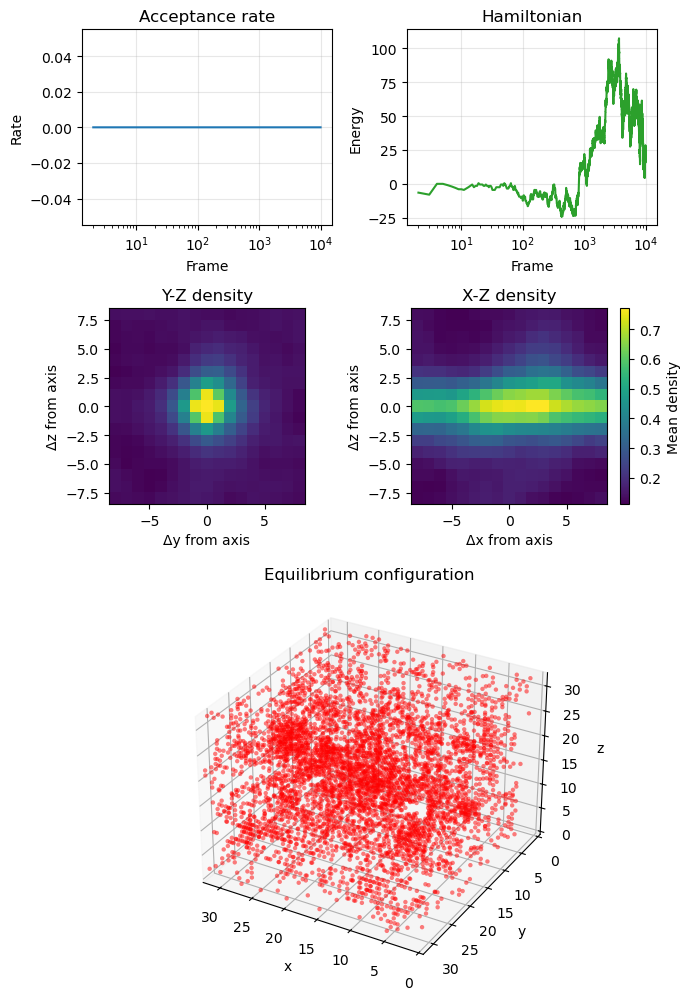

In [223]:
dirname = "20251210/filament_prewetting_32_300-8000"
keyb, keya = 1,10
fig, data = dashboard(dirname, keya, keyb, psize=10, elev=30, azim=120,
        line_pos=[15,15], max_radius=8, xbounds=[13,19], ybounds=[15,17])

#### Concentration profile

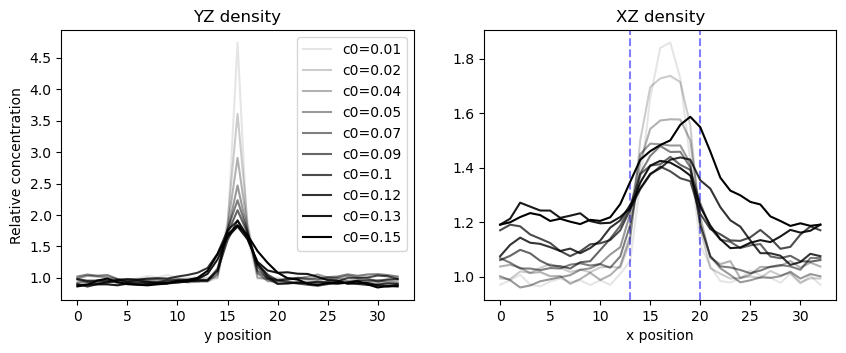

In [203]:
xbounds=[15,17]
ybounds=[14,20]
line_pos=[15,15]
max_radius=16

fig, ax = plt.subplots(1,2, figsize=(10,3.5))

ax[0].set_ylabel("Relative concentration")
ax[0].set_xlabel("y position")
ax[0].set_title("YZ density")

ax[1].set_xlabel("x position")
ax[1].set_title("XZ density")
ax[1].axvline(x=13, linestyle="dashed", color="blue", alpha=0.5)
ax[1].axvline(x=20, linestyle="dashed", color="blue", alpha=0.5)


for keya in range(1, 11):
    data = get_data(dirname, keya, 1)

    dlat = np.array(data["density_lattice"])
    dlat *= data["length"]
    conc = data["length"] / 32**3
    L = dlat.shape[0]
    
    if line_pos is None:
        line_pos = (L // 2, L // 2)
    
    if max_radius is None:
        max_radius = L // 2
    
    # Compute axial density
    xz, extent = densityMap(dlat, line_pos, max_radius=max_radius, 
                                         xbounds=xbounds)
    
    # Compute polar density map
    yz, extent = densityMap(dlat, line_pos, ax=[2,0,1], max_radius=max_radius, 
                                         xbounds=ybounds)
    
    ax[0].plot(range(xz.shape[0]), np.mean(xz, axis=0)/conc, color="black", 
                alpha=0.1*keya, label="c0={}".format(round(conc, 2)))
    ax[1].plot(range(yz.shape[0]), np.mean(yz, axis=0)/conc, color="black", 
                alpha=0.1*keya)
    
    
ax[0].legend()
    

### Prewet enhancers

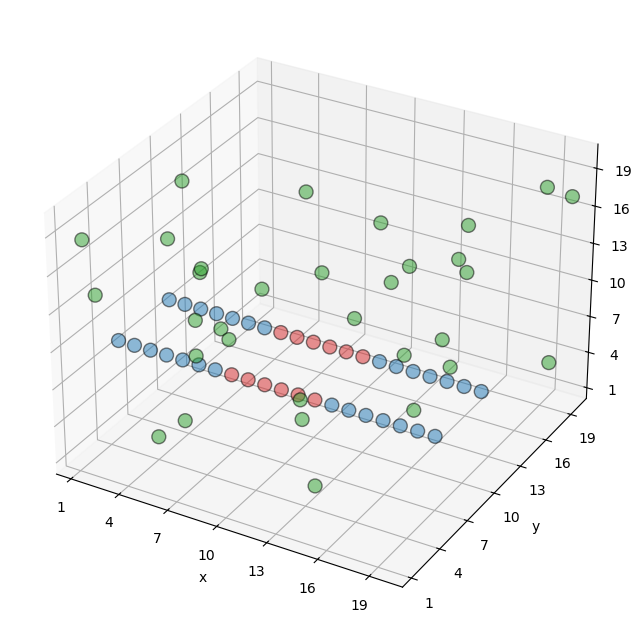

In [ ]:
# import json data

slist = json.load(open("data/"+dirname+".json"))
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
L = int(slist["1"]["boxlength"])
S = 2000
i = 0
for key, val in slist.items():
    arr = np.array(val["coords"])
    l = None

    if len(arr) == 4:
        x, y, z, l = arr
    else:
        x, y, z = arr
    
    # if val["name"][:4] == "poly":
    #     ax.scatter(x-0.5, y-0.5, z-0.5, s=60, c='red', 
    #                marker='o', edgecolor="black", alpha=1)

    ax.scatter(x-0.5, y-0.5, z-0.5, s=S/L, color = colors[i], 
                marker='o', edgecolor="black", alpha=0.5)
        
    if project:
        # projections
        ax.scatter(x-0.45, y-0.55, 0, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(x-0.45, L, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(0, y-0.55, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        
        
    if l is not None and labels:
        for k in range(len(x)):
            ax.text(x[k]-0.5, y[k]-0.5, z[k]-0.5, l[k], size=10)

    i += 1

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, slist["1"]["boxlength"])
ax.set_ylim(0, slist["1"]["boxlength"])
ax.set_zlim(0, slist["1"]["boxlength"])

# Generalized ticks based on lattice size
# Use boxlength as lattice size (integer number of sites per axis)
ticks = np.arange(0.5, L + 0.5, step=min(L, int(L/8)+1))
labels = np.arange(1, L + 1, step=min(L, int(L/8)+1))

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_yticks(ticks)
ax.set_yticklabels(labels)
ax.set_zticks(ticks)
ax.set_zticklabels(labels)
ax.grid(True, which="both")

if adjust_pos:
    ax.view_init(elev=elev, azim=azim)
plt.show()

In [1]:
def dashboard(dirname, keya, keyb, show=True, psize=30, elev=30, azim=120, 
              line_pos=None, max_radius=None,xbounds=None, ybounds=None):
    """
    Plot acceptance rate, ndropation radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """

    res_or_path = 'data/{}/output_cpu{}.json'.format(dirname, keya)
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Concentration: ", res["length"] / res["boxlength"]**3)
    print("Distance: ", keya)

    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")
    

    n = max(len(ham), len(acc))
    frames = np.arange(1, n + 1)

    fig = plt.figure(figsize=(7, 10))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 2])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_ham = fig.add_subplot(gs[0, 1])
    ax_xz = fig.add_subplot(gs[1, 0])
    ax_yz = fig.add_subplot(gs[1, 1])

    if len(acc):
        ax_acc.plot(frames[1:len(acc)-4], acc[1:-4], color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[1:len(ham)-4], ham[1:-4], color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')

    dlat = np.array(res["density_lattice"])
    dlat *= res["length"]
    L = dlat.shape[0]
    
    if line_pos is None:
        line_pos = (L // 2, L // 2)
    
    if max_radius is None:
        max_radius = L // 2
    
    # Compute axial density
    xz_density, extent = densityMap(dlat, line_pos, max_radius=max_radius, 
                                         xbounds=xbounds)
    
    # Compute polar density map
    yz_density, extent = densityMap(dlat, line_pos, ax=[2,0,1], max_radius=max_radius, 
                                         xbounds=xbounds)
    
    
    # Polar cross-section (y-z plane)
    im = ax_xz.imshow(xz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    ax_xz.set_xlabel('Δy from axis')
    ax_xz.set_ylabel('Δz from axis')
    ax_xz.set_title('Y-Z density')
    
    # Polar cross-section (y-z plane)
    im = ax_yz.imshow(yz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    ax_yz.set_xlabel('Δx from axis')
    ax_yz.set_ylabel('Δz from axis')
    ax_yz.set_title('X-Z density')

    # Colorbar
    cbar = plt.colorbar(im, ax=ax_yz)
    cbar.set_label('Mean density')
    
    plt.tight_layout()

    if psize > 20:
        edgecolor = "black"
    else:
        edgecolor = "none"

    # 3D final configuration
    ax3d = fig.add_subplot(gs[2, :], projection='3d')
    x, y, z, _ = res["final_coordinates"] 

    ax3d.scatter(x, y, z, s=psize, c='red', marker='o', edgecolor=edgecolor, alpha=0.5)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Equilibrium configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')
    ax3d.view_init(elev=elev, azim=azim)

    # plt.tight_layout()
    plt.show()
    return fig, res

Species name:  bulk2_g
Concentration:  0.125


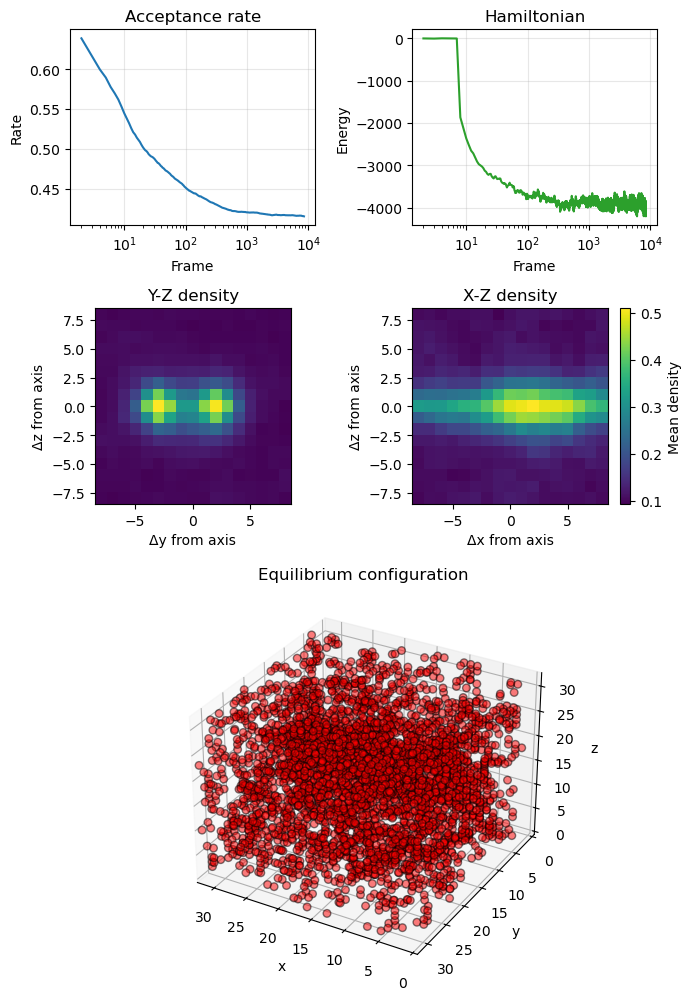

In [161]:
dirname = "20251218/prewet_enhancers_32_4096_1-16"
keyb, keya = 1, 5

fig, data = dashboard(dirname, keya, keyb, psize=30, elev=30, azim=120,
        line_pos=[12,15], max_radius=8, xbounds=[1,20], ybounds=[1,20])

#### Effective force

In [167]:
import numpy as np
import matplotlib.pyplot as plt
import json
from scipy.ndimage import uniform_filter1d


def compute_effective_force(dirname, keya_values, keyb=1, 
                            burn_in_frac=0.5, n_samples=10, thinning=100,
                            smoothing_window=3):
    """
    Compute effective force between prewet filaments from Hamiltonian vs distance.
    
    Parameters
    ----------
    dirname : str
        Directory containing simulation output files
    keya_values : list or array
        List of keya indices (corresponding to different distances)
    keyb : int
        Beta index (usually 1)
    burn_in_frac : float
        Fraction of frames to discard as burn-in
    n_samples : int
        Number of equilibrated samples to take per simulation
    thinning : int
        Number of frames between samples
    smoothing_window : int
        Window size for smoothing (must be odd)
        
    Returns
    -------
    distances : array
        Inter-filament distances
    mean_hams : array
        Mean Hamiltonian at each distance
    std_hams : array
        Standard deviation of Hamiltonian
    ham_smooth : array
        Smoothed Hamiltonian values
    forces : array
        Effective force (negative derivative of energy)
    """
    distances = []
    mean_hams = []
    std_hams = []
    
    for keya in keya_values:
        try:
            res_or_path = 'data/{}/output_cpu{}.json'.format(dirname, keya)
            with open(res_or_path, 'r') as f:
                res_ = json.load(f)
                res = res_[str(keya)][str(keyb)]
            
            ham = np.array(res.get("hamiltonian", []))
            distance = keya  # beta stores the distance
            
            if len(ham) == 0:
                continue
                
            # Compute burn-in index
            burn_in_idx = int(len(ham) * burn_in_frac)
            
            # Sample equilibrated values with thinning
            equilibrated = ham[burn_in_idx:]
            
            # Take n_samples evenly spaced (with thinning)
            if len(equilibrated) > n_samples * thinning:
                sample_indices = np.arange(0, n_samples * thinning, thinning)
                samples = equilibrated[sample_indices]
            else:
                # If not enough data, take what we can
                samples = equilibrated[::max(1, len(equilibrated) // n_samples)]
            
            distances.append(distance)
            mean_hams.append(np.mean(samples))
            std_hams.append(np.std(samples) / np.sqrt(len(samples)))  # standard error
            
        except Exception as e:
            print(f"Error loading keya={keya}: {e}")
            continue
    
    # Convert to arrays and sort by distance
    distances = np.array(distances)
    mean_hams = np.array(mean_hams)
    std_hams = np.array(std_hams)
    
    sort_idx = np.argsort(distances)
    distances = distances[sort_idx]
    mean_hams = mean_hams[sort_idx]
    std_hams = std_hams[sort_idx]
    
    # Smooth the Hamiltonian curve
    if smoothing_window > 1 and len(mean_hams) >= smoothing_window:
        ham_smooth = uniform_filter1d(mean_hams, size=smoothing_window, mode='nearest')
    else:
        ham_smooth = mean_hams.copy()
    
    # Compute force as negative derivative: F = -dH/dr
    # Use central differences where possible
    forces = np.zeros_like(ham_smooth)
    if len(distances) > 2:
        # Central difference for interior points
        for i in range(1, len(distances) - 1):
            dr = distances[i+1] - distances[i-1]
            if dr > 0:
                forces[i] = -(ham_smooth[i+1] - ham_smooth[i-1]) / dr
        
        # Forward/backward difference for endpoints
        if distances[1] != distances[0]:
            forces[0] = -(ham_smooth[1] - ham_smooth[0]) / (distances[1] - distances[0])
        if distances[-1] != distances[-2]:
            forces[-1] = -(ham_smooth[-1] - ham_smooth[-2]) / (distances[-1] - distances[-2])
    
    return distances, mean_hams, std_hams, ham_smooth, forces


def plot_effective_force(dirname, keya_values, keyb=1, 
                         burn_in_frac=0.5, n_samples=10, thinning=100,
                         smoothing_window=3, figsize=(12, 5)):
    """
    Plot Hamiltonian vs distance and effective force between filaments.
    """
    distances, mean_hams, std_hams, ham_smooth, forces = compute_effective_force(
        dirname, keya_values, keyb, burn_in_frac, n_samples, thinning, smoothing_window
    )
    
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    
    # Plot 1: Raw Hamiltonian vs distance
    axes[0].errorbar(distances, mean_hams, yerr=std_hams, fmt='o', 
                     color='C0', capsize=3, markersize=5, label='Mean H')
    axes[0].plot(distances, ham_smooth, '-', color='C1', linewidth=2, 
                 label=f'Smoothed (w={smoothing_window})')
    axes[0].set_xlabel('Inter-filament distance')
    axes[0].set_ylabel('Hamiltonian')
    axes[0].set_title('Energy vs Distance')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot 2: Effective force vs distance
    axes[1].plot(distances, forces, 'o-', color='C2', markersize=5, linewidth=2)
    axes[1].axhline(y=0, color='black', linestyle='--', alpha=0.5)
    axes[1].set_xlabel('Inter-filament distance')
    axes[1].set_ylabel('Force (F = -dH/dr)')
    axes[1].set_title('Effective Inter-filament Force')
    axes[1].grid(True, alpha=0.3)
    
    # Annotate attractive/repulsive regions
    if np.any(forces > 0) and np.any(forces < 0):
        axes[1].fill_between(distances, forces, 0, where=(forces > 0), 
                            alpha=0.3, color='red', label='Repulsive')
        axes[1].fill_between(distances, forces, 0, where=(forces < 0), 
                            alpha=0.3, color='blue', label='Attractive')
        axes[1].legend()
    
    # # Plot 3: Potential well visualization
    # # Shift energy so minimum is at zero
    # ham_shifted = ham_smooth - np.min(ham_smooth)
    # axes[2].plot(distances, ham_shifted, 'o-', color='C3', markersize=5, linewidth=2)
    # axes[2].set_xlabel('Inter-filament distance')
    # axes[2].set_ylabel('H - H_min')
    # axes[2].set_title('Effective Potential Well')
    # axes[2].grid(True, alpha=0.3)
    
    # # Mark the equilibrium distance (minimum energy)
    # eq_idx = np.argmin(ham_smooth)
    # axes[2].axvline(x=distances[eq_idx], color='green', linestyle='--', 
    #                 alpha=0.7, label=f'Equilibrium d={distances[eq_idx]:.1f}')
    # axes[2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    # print(f"Equilibrium distance: {distances[eq_idx]:.2f}")
    # print(f"Minimum energy: {ham_smooth[eq_idx]:.2f}")
    print(f"Energy range: {np.min(ham_smooth):.2f} to {np.max(ham_smooth):.2f}")
    print(f"Max attractive force: {np.min(forces):.4f}")
    print(f"Max repulsive force: {np.max(forces):.4f}")
    
    return fig, (distances, mean_hams, std_hams, ham_smooth, forces)


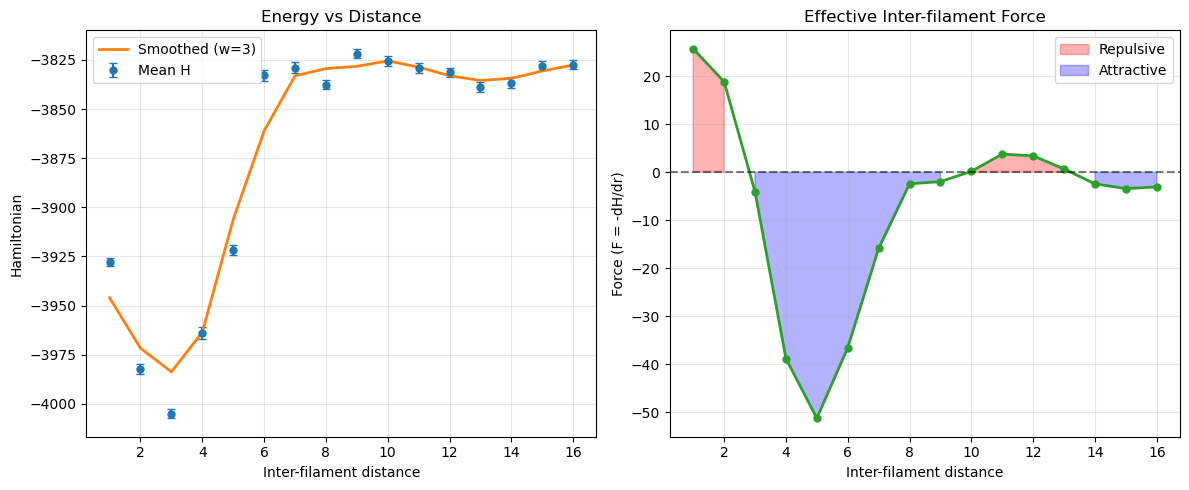

Energy range: -3983.70 to -3825.47
Max attractive force: -51.2172
Max repulsive force: 25.6963


In [168]:
# Example usage
if __name__ == "__main__":
    dirname = "20251218/prewet_enhancers_32_4096_1-16"
    keya_values = list(range(1, 17))  # Adjust based on your actual keya range

    fig, results = plot_effective_force(
        dirname, 
        keya_values,
        keyb=1,
        burn_in_frac=0.5,      # Discard first 50% as burn-in
        n_samples=1000,           # Take 20 samples from equilibrated region
        thinning=10,            # 50 frames between samples
        smoothing_window=3      # Smooth over 3 points
    )

    distances, mean_hams, std_hams, ham_smooth, forces = results


In [169]:
out_dir = "media/figures/20251218"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "prewetting_attraction_force.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20251218/prewetting_attraction_force.pdf


### Prewetting & regulation

In [170]:
dirname = "20251208/test_frame1"
labels, project =False, False
adjust_pos, elev, azim = False, 0, 90  # default is 30, 120
# colors = ["C0", "C0", "C3", "C2", "C0", "C3", "C0"]
colors = {"a":"C0", "b":"C0", "c":"C1", 
          "d":"C0", "e":"C0", "f":"C4", "g":"C2", "h":"C3"}

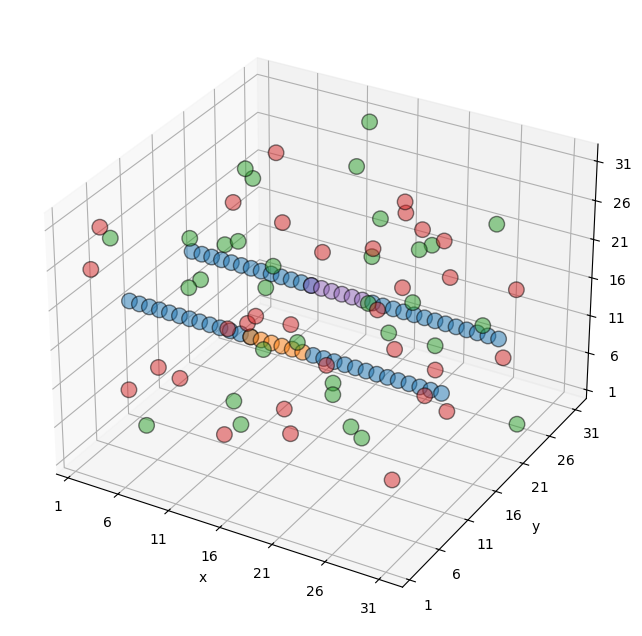

In [171]:
# import json data

slist = json.load(open("data/"+dirname+".json"))
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
L = int(slist["1"]["boxlength"])
S = 4000
i = 0
for key, val in slist.items():
    arr = np.array(val["coords"])
    l = None

    if len(arr) == 4:
        x, y, z, l = arr
    else:
        x, y, z = arr
    
    # if val["name"][:4] == "poly":
    #     ax.scatter(x-0.5, y-0.5, z-0.5, s=60, c='red', 
    #                marker='o', edgecolor="black", alpha=1)

    sp_name = val["name"][-1]

    ax.scatter(x-0.5, y-0.5, z-0.5, s=S/L, color = colors[sp_name], 
                marker='o', edgecolor="black", alpha=0.5)
        
    if project:
        # projections
        ax.scatter(x-0.45, y-0.55, 0, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(x-0.45, L, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        ax.scatter(0, y-0.55, z-0.45, s=50, color = 'black', 
                    marker='.', edgecolor="black", alpha=0.2)
        
        
    if l is not None and labels:
        for k in range(len(x)):
            ax.text(x[k]-0.5, y[k]-0.5, z[k]-0.5, l[k], size=10)

    i += 1

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, slist["1"]["boxlength"])
ax.set_ylim(0, slist["1"]["boxlength"])
ax.set_zlim(0, slist["1"]["boxlength"])

# Generalized ticks based on lattice size
# Use boxlength as lattice size (integer number of sites per axis)
ticks = np.arange(0.5, L + 0.5, step=min(L, int(L/8)+1))
labels = np.arange(1, L + 1, step=min(L, int(L/8)+1))

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_yticks(ticks)
ax.set_yticklabels(labels)
ax.set_zticks(ticks)
ax.set_zticklabels(labels)
ax.grid(True, which="both")

if adjust_pos:
    ax.view_init(elev=elev, azim=azim)
plt.show()

In [172]:
out_dir = "media/figures/20251218"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "prewetting_regulation_setup.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20251218/prewetting_regulation_setup.pdf


In [196]:
def dashboard(dirname, keya, keyb, show=True, psize=30, elev=30, azim=120, 
              line_pos=None, max_radius=None,xbounds=None, ybounds=None):
    """
    Plot acceptance rate, ndropation radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """

    res_or_path = 'data/{}/output_cpu{}.json'.format(dirname, keya)
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Concentration: ", res["length"] / res["boxlength"]**3)

    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")
    

    n = max(len(ham), len(acc))
    frames = np.arange(1, n + 1)

    fig = plt.figure(figsize=(7, 10))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 2])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_ham = fig.add_subplot(gs[0, 1])
    ax_xz = fig.add_subplot(gs[1, 0])
    ax_yz = fig.add_subplot(gs[1, 1])

    if len(acc):
        ax_acc.plot(frames[1:len(acc)-4], acc[1:-4], color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[1:len(ham)-4], ham[1:-4], color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')

    dlat = np.array(res["tf_density_lattice"])
    dlat *= res["length"]
    L = dlat.shape[0]
    
    if line_pos is None:
        line_pos = (L // 2, L // 2)
    
    if max_radius is None:
        max_radius = L // 2
    
    # Compute axial density
    xz_density, extent = densityMap(dlat, line_pos, max_radius=max_radius, 
                                         xbounds=xbounds)
    
    # Compute polar density map
    yz_density, extent = densityMap(dlat, line_pos, ax=[2,0,1], max_radius=max_radius, 
                                         xbounds=xbounds)
    
    
    # Polar cross-section (y-z plane)
    im = ax_xz.imshow(xz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    ax_xz.set_xlabel('Δy from axis')
    ax_xz.set_ylabel('Δz from axis')
    ax_xz.set_title('Y-Z density')
    
    # Polar cross-section (y-z plane)
    im = ax_yz.imshow(yz_density, origin='lower', extent=extent, 
                        cmap='viridis', aspect='equal')
    ax_yz.set_xlabel('Δx from axis')
    ax_yz.set_ylabel('Δz from axis')
    ax_yz.set_title('X-Z density')

    # Colorbar
    cbar = plt.colorbar(im, ax=ax_yz)
    cbar.set_label('Mean density')
    
    plt.tight_layout()

    if psize > 20:
        edgecolor = "black"
    else:
        edgecolor = "none"

    # 3D final configuration
    ax3d = fig.add_subplot(gs[2, :], projection='3d')
    x, y, z, _ = res["tf_final_coordinates"] 

    ax3d.scatter(x, y, z, s=psize, c='red', marker='o', edgecolor=edgecolor, alpha=0.5)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Equilibrium configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')
    ax3d.view_init(elev=elev, azim=azim)

    # plt.tight_layout()
    plt.show()
    return fig, res

In [214]:
dirname = "20251218/prewet_transcription_32_1300-4000"
keyb, keya = 1, 5
data = get_data(dirname, keya, keyb)
xz, yz = plotAxialDensity(data, [15,15], max_radius=16, 
        xbounds=[6,16], ybounds=[6,16], key="rnap_density_lattice")

TypeError: unsupported operand type(s) for +: 'float' and 'NoneType'

In [215]:
data["rnap_density_lattice"]

[[[None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None],
  [None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None],
  [None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None],
  [None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None,
   None

In [202]:
dirname = "20251218/prewet_transcription_32_1300-4000"
keyb, keya = 1, 16
data = get_data(dirname, keya, keyb)

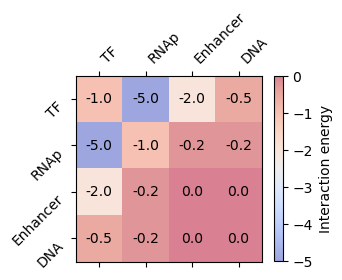

In [ ]:
# intmat = np.array([[-1.0,-5.0,-2.0,-0.5],
#                    [-5.0,-1.0,-0.2,-0.2],
#                    [-2.0,-0.2, 0.0, 0.0],
#                    [-0.5,-0.2, 0.0, 0.0]])
intmat = np.array(data["interaction_matrix"])
labels = ["TF", "RNAp", "Enhancer", "Promoter", "DNA"]

fig, ax = plt.subplots(figsize=(3, 3))

im = ax.matshow(intmat, cmap="coolwarm", alpha=0.5)
ax.set_xticks(range(4))
ax.set_xticklabels(labels, rotation=45, ha="left")
ax.set_yticks(range(4))
ax.set_yticklabels(labels, rotation=45, va="top")

for (i, j), val in np.ndenumerate(intmat):
    ax.text(j, i, val, ha='center', va='center')
cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Interaction energy')
plt.show()

TF concentration:  0.1220703125


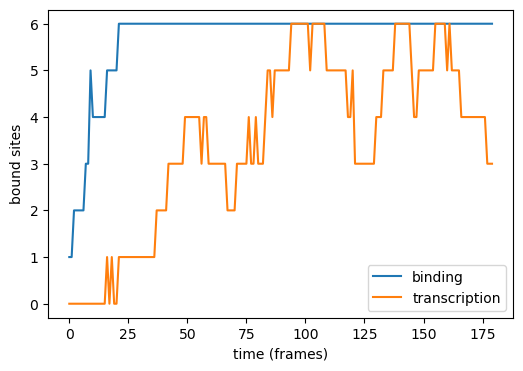

In [190]:
fig, ax = plt.subplots(1,1, figsize=(6,4))

transcription = np.array(data["transcription"])
binding = np.array(data["binding"])

ax.plot(binding, label = "binding")
ax.plot(transcription, label = "transcription")
ax.set_xlabel("time (frames)")
ax.set_ylabel("bound sites")
ax.legend()
print("TF concentration: ", data["length"] / data["boxlength"] ** 3)

In [ ]:
traces = {}
for keya in range(1,17):

    data = get_data(dirname, keya, keyb)
    transcription = np.array(data["transcription"])
    conc = data["length"] / data["boxlength"] ** 3
    traces[keya] = {"c": conc,
                    "mean": np.mean(transcription),
                    "var": np.var(transcription)}

In [ ]:
# accumulated transcription estimate of fisher information rate
def fisher_rate_bp(trace):
    var = np.var(trace) / len(trace)
    

#### Polymer

In [ ]:
def plot_simulation_dashboard(res_or_path, keya, keyb, show=True, psize=30):
# dlat is a 3D lattice of densities at each site (shape: L x L x L)
    """
    Plot acceptance rate, gyration radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Interaction potential: ", res["alpha"])
    print("Chemical potential: ", res["beta"])

    gyr = to_np("gyration_radius")
    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")

    if "polymer_length" in res.keys():
        plen = to_np("polymer_length")
    elif "length" in res.keys():
        plen = to_np("length") * np.ones(len(acc))

    n = max(len(gyr), len(plen), len(ham), len(acc))
    frames = np.arange(1, n + 1)

    fig = plt.figure(figsize=(7, 10))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 2])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_gyr = fig.add_subplot(gs[0, 1])
    ax_ham = fig.add_subplot(gs[1, 1])
    ax_len = fig.add_subplot(gs[1, 0])

    if len(acc):
        ax_acc.plot(frames[1:len(acc)], acc[1:], color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(gyr):
        ax_gyr.plot(frames[1:len(gyr)], gyr[1:], color='C1')
    ax_gyr.set_title('Gyration radius')
    ax_gyr.set_xlabel('Frame')
    ax_gyr.set_ylabel('Radius')
    ax_gyr.grid(True, alpha=0.3)
    ax_gyr.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[1:len(ham)], ham[1:], color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')

    if len(plen):
        ax_len.plot(frames[1:len(plen)], plen[1:], color='C3')
    ax_len.set_title('Polymer length')
    ax_len.set_xlabel('Frame')
    ax_len.set_ylabel('Length')
    ax_len.grid(True, alpha=0.3)
    ax_len.set_xscale('log')

    # 3D final configuration
    ax3d = fig.add_subplot(gs[2, :], projection='3d')
    x, y, z = res["final_coordinates"]
    
    ax3d.scatter(x, y, z, s=psize, c='red', marker='o', edgecolor='black', alpha=1)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Final polymer configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')

    plt.tight_layout()
    if show:
        plt.show()
    return fig

Species name:  poly2
Interaction potential:  -0.75
Chemical potential:  1.0


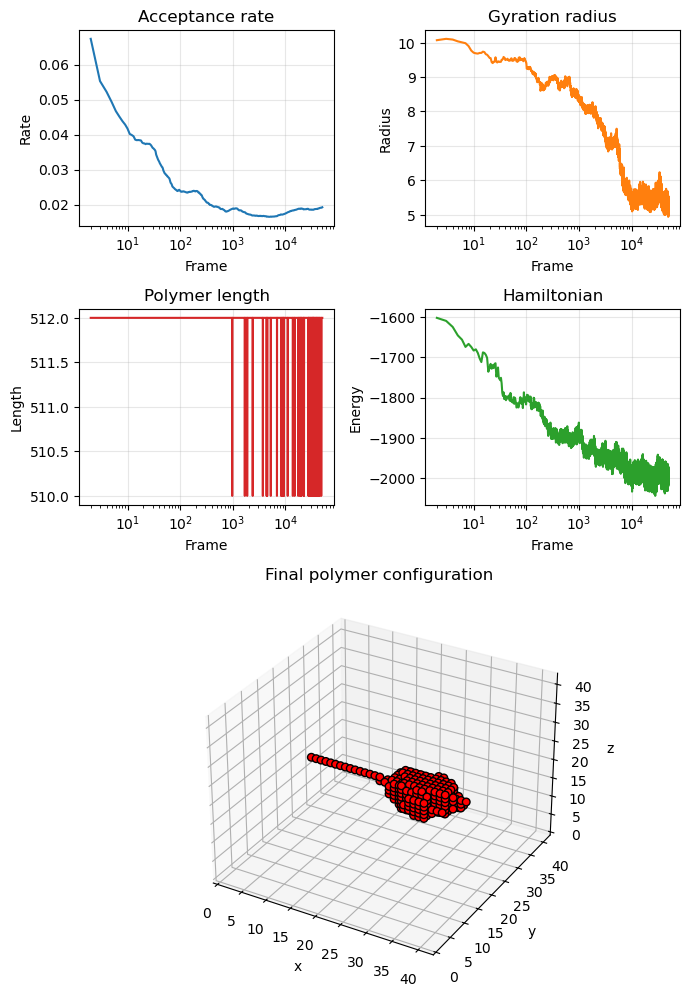

In [194]:
# Example usage:
alpha_index = 8
beta_index = 1
fig = plot_simulation_dashboard('data/20251101/radius_intpot_8h/radius_intpot_cpu{}.json'.format(alpha_index), 
                                alpha_index, beta_index)

In [192]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "polymer_dashboard_8.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/polymer_dashboard_8.pdf


#### Phase transition with respect to interaction potential

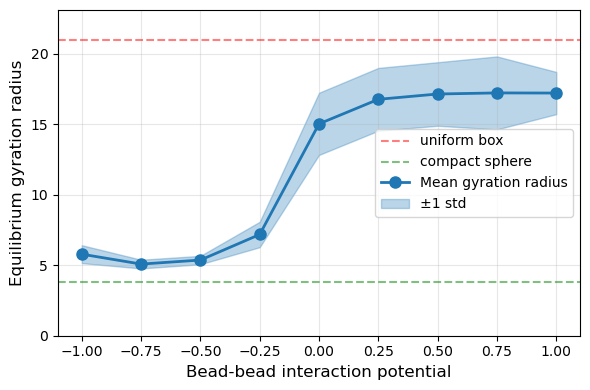

Interaction Potential → Mean Gyration Radius ± Std Dev:
  β = -1.00 → 5.784 ± 0.635 (n=35)
  β = -0.75 → 5.081 ± 0.309 (n=35)
  β = -0.50 → 5.366 ± 0.298 (n=35)
  β = -0.25 → 7.179 ± 0.901 (n=35)
  β =  0.00 → 15.026 ± 2.204 (n=35)
  β =  0.25 → 16.766 ± 2.226 (n=35)
  β =  0.50 → 17.142 ± 2.253 (n=35)
  β =  0.75 → 17.220 ± 2.587 (n=35)
  β =  1.00 → 17.210 ± 1.498 (n=35)


In [167]:
import glob
from collections import defaultdict

# Load all JSON files from the directory
def plot_order_param(data_dir, warmup=None, thinning=None):
    json_files = sorted(glob.glob(os.path.join(data_dir, "*.json")))

    # Dictionary to store gyration radii grouped by interaction potential
    alpha_to_gyr = defaultdict(list)

    # Read all files and extract final gyration radius and alpha values
    for json_file in json_files:
        with open(json_file, 'r') as f:
            data = json.load(f)
            # Iterate through all alpha and beta combinations in each file
            for alpha_key in data.keys():
                for beta_key in data[alpha_key].keys():
                    result = data[alpha_key][beta_key]
                    alpha = result.get("alpha", None)
                    gyr = result.get("gyration_radius", [])

                    if warmup is None:
                        warmup = int(result["nframes"]/5)
                    
                    if thinning is None:
                        thinning = int(result["nframes"]/5)
                    
                    if alpha is not None and len(gyr) > 0:
                        # Get samples of gyration radius at equilibrium
                        for i in range(5):
                            final_gyr = gyr[warmup+i*thinning-1]
                            alpha_to_gyr[alpha].append(final_gyr)

    # Calculate mean and std for each alpha value
    alphas = sorted(alpha_to_gyr.keys())
    means = [np.mean(alpha_to_gyr[b]) for b in alphas]
    stds = [np.std(alpha_to_gyr[b]) for b in alphas]

    # Create the plot
    fig, ax = plt.subplots(figsize=(6, 4))

    # Radius of compacted sphere
    if "maxlength" in result.keys():
        length = result["maxlength"]
    elif "length" in result.keys():
        length = result["length"]
        
    boxlength = result["boxlength"]
    radius = (3*length/(4*np.pi))**(1/3)
    Rg_sphere = np.sqrt(3/5)*radius
    Rg_box = boxlength / 2
    ax.axhline(y=Rg_box, linestyle="dashed", color="red", label="uniform box", alpha=0.5)
    ax.axhline(y=Rg_sphere, linestyle="dashed", color="green", label="compact sphere", alpha=0.5)

    # Plot mean line
    ax.plot(alphas, means, 'o-', linewidth=2, markersize=8, color='C0', label='Mean gyration radius')

    # Add shaded error region (±1 std)
    ax.fill_between(alphas, 
                    np.array(means) - np.array(stds), 
                    np.array(means) + np.array(stds), 
                    alpha=0.3, color='C0', label='±1 std')

    ax.set_xlabel('Bead-bead interaction potential', fontsize=12)
    ax.set_ylabel('Equilibrium gyration radius', fontsize=12)
    # ax.set_title('Gyration Radius vs Interaction Potential', fontsize=14)
    ax.set_ylim(0, Rg_box*1.1)
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # Print statistics
    print("Interaction Potential → Mean Gyration Radius ± Std Dev:")
    for b, m, s in zip(alphas, means, stds):
        print(f"  β = {b:5.2f} → {m:.3f} ± {s:.3f} (n={len(alpha_to_gyr[b])})")

plot_order_param(data_dir = "data/20251101/radius_intpot")

In [113]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "radius_gyration_vs_interaction_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/radius_gyration_vs_interaction_potential.pdf


#### Bulk

Species name:  bulk2
Interaction potential:  -1.0
Chemical potential:  1.0


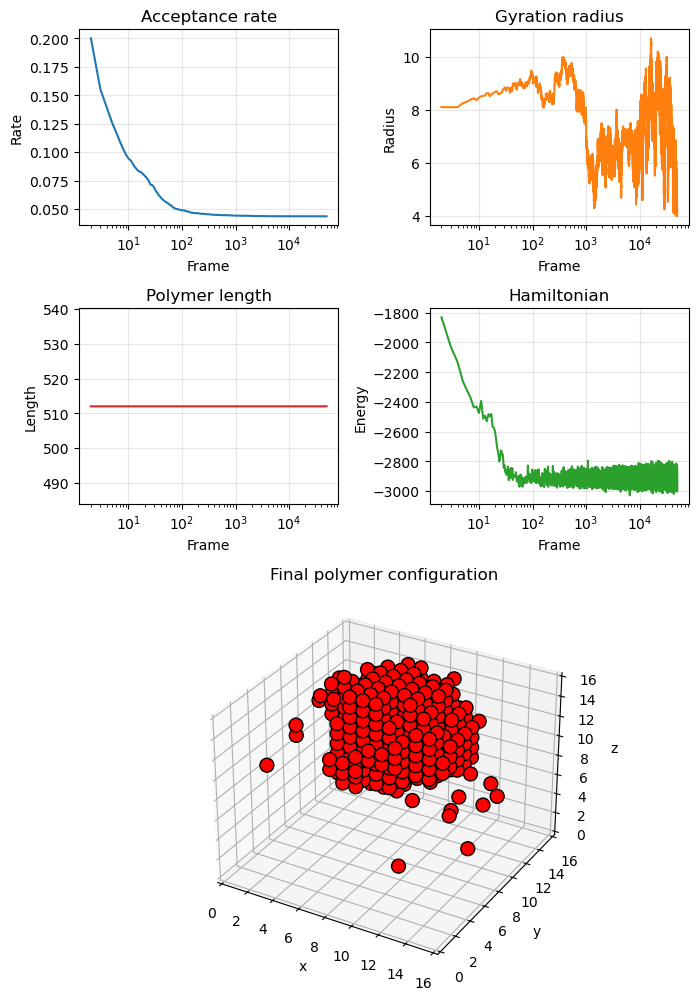

In [184]:
# Example usage:
alpha_index = 1
beta_index = 1
fig = plot_simulation_dashboard('data/20251104/bulk_phases_45m/output_cpu{}.json'.format(alpha_index), 
                                alpha_index, beta_index, psize=100)

In [180]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "bulk_dashboard_4.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/bulk_dashboard_4.pdf


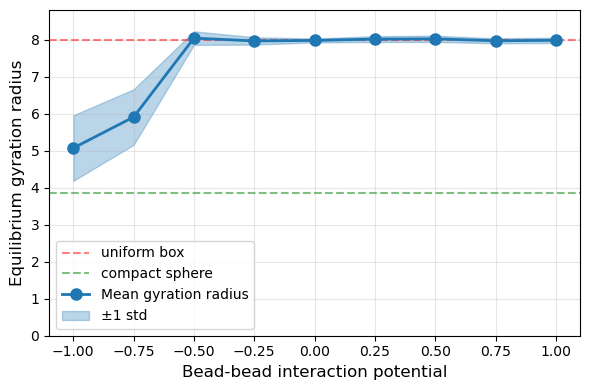

Interaction Potential → Mean Gyration Radius ± Std Dev:
  β = -1.00 → 5.070 ± 0.885 (n=5)
  β = -0.75 → 5.908 ± 0.750 (n=5)
  β = -0.50 → 8.041 ± 0.183 (n=5)
  β = -0.25 → 7.965 ± 0.100 (n=5)
  β =  0.00 → 7.977 ± 0.052 (n=5)
  β =  0.25 → 8.014 ± 0.080 (n=5)
  β =  0.50 → 8.021 ± 0.085 (n=5)
  β =  0.75 → 7.969 ± 0.068 (n=5)
  β =  1.00 → 7.981 ± 0.073 (n=5)


In [181]:
plot_order_param(data_dir = "data/20251104/bulk_phases_45m",
                 warmup = 40000, thinning = 2000)

In [182]:
out_dir = "media/figures"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "bulk_radius_gyration_vs_interaction_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/bulk_radius_gyration_vs_interaction_potential.pdf


## Droplet phase diagram

In [77]:
def dashboard(dirname, keya, keyb, show=True, psize=30, elev=30, azim=120):
    """
    Plot acceptance rate, ndropation radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """

    res_or_path = 'data/{}/output_cpu{}.json'.format(dirname, keya)
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Temperature: ", res["temperature"])
    print("Chem./int. potential: ", res["beta"])

    ndrop = to_np("ndroplets")
    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")
    bdens = to_np("dilute_density")
    ddens = to_np("droplet_density")
    

    n = max(len(ndrop), len(ham), len(acc))
    frames = np.arange(1, n + 1)
    dsize = np.zeros(n)

    for i, x in enumerate(res["droplet_sizes"]): 
        if x == []:
            dsize[i] = None
        else:
            dsize[i] = max(x)

    fig = plt.figure(figsize=(7, 12))
    gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 2])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_ham = fig.add_subplot(gs[0, 1])
    ax_ndrop = fig.add_subplot(gs[1, 1])
    ax_size = fig.add_subplot(gs[1, 0])
    ax_ddens = fig.add_subplot(gs[2, 1])
    ax_bdens = fig.add_subplot(gs[2, 0])

    if len(acc):
        ax_acc.plot(frames[1:len(acc)-4], acc[1:-4], color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(ndrop):
        ax_ndrop.plot(frames[1:len(ndrop)-4], ndrop[1:-4], color='C1')
    ax_ndrop.set_title('Number of droplets')
    ax_ndrop.set_xlabel('Frame')
    ax_ndrop.set_ylabel('Ndroplets')
    ax_ndrop.grid(True, alpha=0.3)
    ax_ndrop.set_xscale('log')

    if len(bdens):
        ax_bdens.plot(frames[1:len(bdens)-4], bdens[1:-4], color='C5')
    ax_bdens.set_title('Dilute density')
    ax_bdens.set_xlabel('Frame')
    ax_bdens.set_ylabel('Density')
    ax_bdens.grid(True, alpha=0.3)
    ax_bdens.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[1:len(ham)-4], ham[1:-4], color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')

    if len(dsize):
        ax_size.plot(frames[1:len(dsize)-4], dsize[1:-4], color='C3')
    ax_size.set_title('Max droplet size')
    ax_size.set_xlabel('Frame')
    ax_size.set_ylabel('Length')
    ax_size.grid(True, alpha=0.3)
    ax_size.set_xscale('log')

    if len(ddens):
        ax_ddens.plot(frames[1:len(ddens)-4], ddens[1:-4], color='C4')
    ax_ddens.set_title('Droplet density')
    ax_ddens.set_xlabel('Frame')
    ax_ddens.set_ylabel('Length')
    ax_ddens.grid(True, alpha=0.3)
    ax_ddens.set_xscale('log')

    if psize > 20:
        edgecolor = "black"
    else:
        edgecolor = "none"

    # 3D final configuration
    ax3d = fig.add_subplot(gs[3, :], projection='3d')
    x, y, z, _ = res["final_coordinates"]
    # xb, yb, zb, _ = res["final_coordinates_b"]
    # xc, yc, zc, _ = res["final_coordinates_c"]
    # xd, yd, zd, _ = res["final_coordinates_d"]    

    ax3d.scatter(x, y, z, s=psize, c='red', marker='o', edgecolor=edgecolor, alpha=0.5)
    # ax3d.scatter(xb, yb, zb, s=psize, c='blue', marker='o', edgecolor=edgecolor, alpha=0.5)
    # ax3d.scatter(xc, yc, zc, s=psize, c='blue', marker='o', edgecolor=edgecolor, alpha=0.5)
    # ax3d.scatter(xd, yd, zd, s=psize, c='green', marker='o', edgecolor=edgecolor, alpha=0.5)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Equilibrium configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')
    ax3d.view_init(elev=elev, azim=azim)

    plt.tight_layout()
    if show:
        plt.show()
    return fig, res

Species name:  bulk2_a
Temperature:  1.4
Chem./int. potential:  0.0


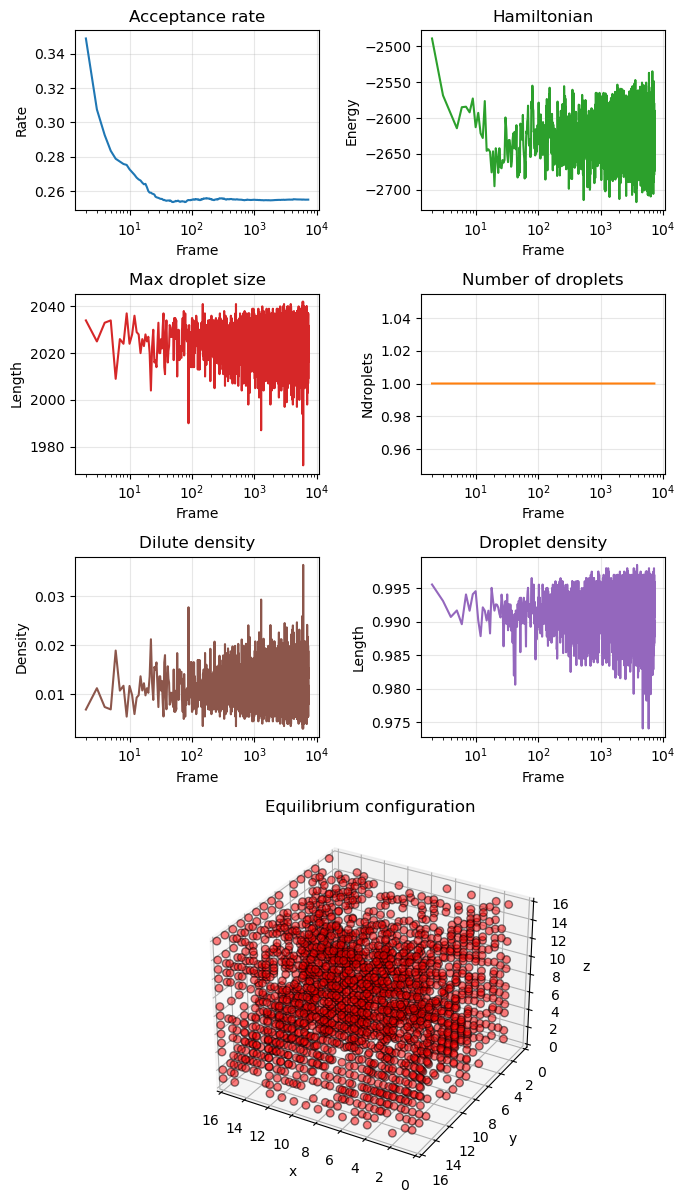

In [78]:
# Example usage:
alpha_index = 14
beta_index = 1
# dirname = "20251210/filament_prewetting_32_124-1024"
dirname = "20251217/flory_huggins_16_2048_0.1-1.6"
# dirname = "20251126/flory_huggins_16_512"
# dirname = "20251125/flory_huggins_23_1500"
fig, data = dashboard(dirname, alpha_index, beta_index, psize=30, elev=30, azim=120)

In [201]:
np.mean(data["dilute_density"][10000:])

0.0341333669061536

## Animations

#### Example

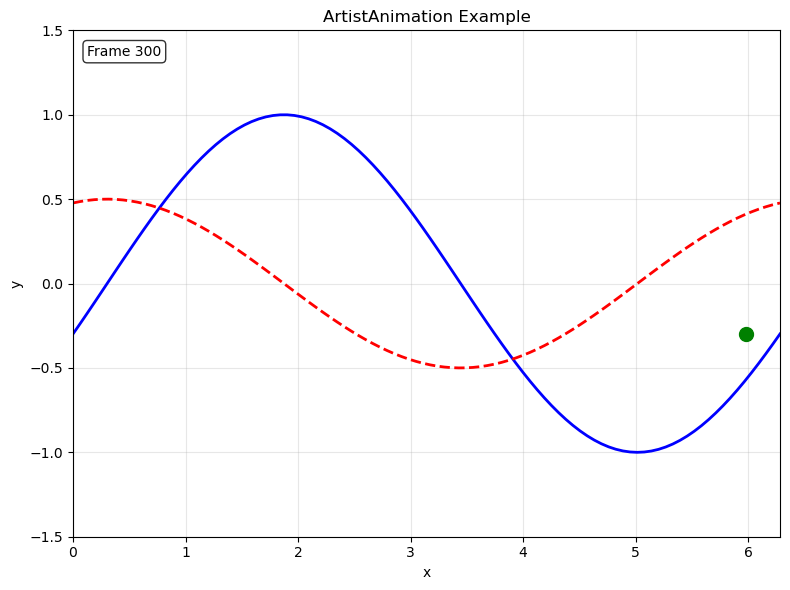

In [ ]:
# Basic example of ArtistAnimation in matplotlib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Create figure and axis
fig, ax = plt.subplots(figsize=(8, 6))

# Generate data for animation
x = np.linspace(0, 2*np.pi, 100)
frames = []

# Create a series of artists for each frame
for i in range(300):
    # Create different artists for this frame
    phase = i * 0.02
    y1 = np.sin(x + phase)
    y2 = np.cos(x + phase) * 0.5
    
    # Plot multiple elements as artists
    line1, = ax.plot(x, y1, 'b-', linewidth=2, label='sin wave')
    line2, = ax.plot(x, y2, 'r--', linewidth=2, label='cos wave')
    scatter = ax.scatter([phase], [np.sin(phase)], c='green', s=100, zorder=5)
    text = ax.text(0.02, 0.95, f'Frame {i+1}', transform=ax.transAxes, 
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Group all artists for this frame
    frame_artists = [line1, line2, scatter, text]
    frames.append(frame_artists)

# Set up the plot
ax.set_xlim(0, 2*np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('ArtistAnimation Example')
ax.grid(True, alpha=0.3)

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=100, blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

# Optional: Save as GIF (uncomment if needed)
anim.save('media/sinewaves.gif', writer='pillow', fps=25)

#### Polymer

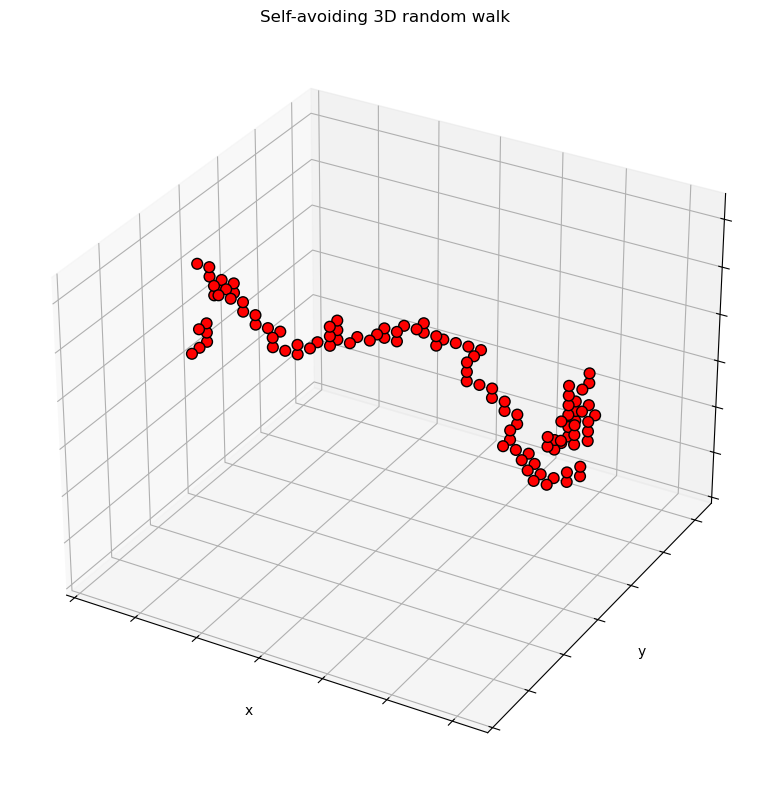

In [42]:
# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
dirname = "20251024/testpoly" 

frames = []

for i in range(2000):
    lattice = json.load(open("data/"+dirname+"_frame"+str(i+1)+".json"))
    lattice = np.array(lattice)

    # Get coordinates where array == 1
    coords = np.argwhere(lattice[..., -2] == 1)
    x, y, z = coords[:, 2], coords[:, 1], coords[:, 0]

    scatter = ax.scatter(x, y, z, s=60, c='red', marker='o', edgecolor="black", alpha=1)

    frame_artists = [scatter]
    frames.append(frame_artists)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=10, 
                                 blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

anim.save('media/polymer_repulsive.mp4', writer="ffmpeg", fps=25)

## Sandbox

### Flory-Huggins

In [44]:
import numdifftools as nd
from scipy import optimize as opt

###### Define basic functions

# Flory-Huggins free energy
def F(phi, *args):
    mu, chi, T = args
    return -mu*phi + 6*chi*phi**2 + T*(phi*np.log(phi) + (1-phi)*np.log(1-phi))

# Difference between F and tangent
def G(phi, *args):
    mu, chi, T, m, b = args
    return F(phi, mu, chi, T) - m*phi - b

# Its derivative
dG = nd.Derivative(G)

# Positive part of difference between line and curve
def fun(m, b, fvals, phis, beta):
    line = phis * m + b
    overshoot = (np.abs(line - fvals) + (line - fvals)) / 2

    return np.sum(line) - beta * np.sum(overshoot)

def loss(x, *args):
    m, b = x
    fvals = F(phis, *args)

    return  - fun(m, b, fvals, phis, 100)


###### Maximize area under a line, with a hard penalty on going over the F curve

# Find the tangent points: zeros of the diff's derivative
def solve_fh(phis, mu, chi, T):
    x0 = [-1, 0]
    res = opt.minimize(loss, x0, args=(mu,chi,T), method='Nelder-Mead', tol=1e-6)
    m, b = res.x

    # Evaluate it pointwise on the grid of phi values
    dGvals = np.array([dG(p, mu, chi, T, m, b) for p in phis])

    # find sign changes
    zeros = np.where(dGvals[1:] * np.roll(dGvals, 1)[1:] < 0)[0]

    # solutions
    sol = [phis[z] for z in zeros]

    if len(sol) == 3:
        return np.array([sol[0], sol[2]])
    elif len(sol) == 1:
        return np.array([sol[0]])
    else:
        print("No solutions!")
        return None


In [45]:
T = 2.5
mu = 5.0
chi = -1.0
eps = 5e-3
ngrid = 500
phis = np.linspace(eps, 1-eps, ngrid)

sol = solve_fh(phis, mu, chi, T)

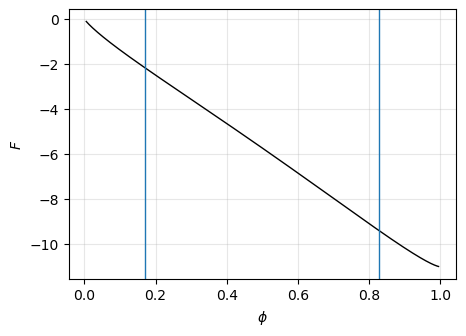

In [46]:
###### Plot

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

ax.plot(phis, F(phis, mu, chi, T), color="black", lw=1)
# ax.plot(phis, m*phis + b, lw=1)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$F$")
ax.grid(True, alpha=0.3)

if sol is not None:
    if len(sol) == 2:
        ax.axvline(x=sol[0], lw=1)
        ax.axvline(x=sol[1], lw=1)
    elif len(sol) == 1:
        ax.axvline(x=sol[0], lw=1)

### Phase diagram

In [ ]:
mu = 0.0
chi = -1.0
eps = 5e-3
ngrid = 200
phis = np.linspace(eps, 1-eps, ngrid)

Tvals = np.linspace(1.05,3, 500)
sols = []

for T in Tvals:
    sol = solve_fh(phis, mu, chi, T)

    if len(sol) == 2:
        sols.append(sol)
    else:
        sols.append([None, None])

In [75]:
def to_np(key):
    arr = np.array(res.get(key, []))
    return arr

Tvals = np.linspace(1.05,3, 500)

# alphas = [1,2,3,11,12,14]
alphas = np.arange(1, 17)
# dirname = "20251125/flory_huggins_23_1500"
dirname = "20251217/flory_huggins_16_512_0.1-1.6"
bdens_means = np.zeros(len(alphas))
bdens_stds = np.zeros(len(alphas))
ddens_means = np.zeros(len(alphas))
ddens_stds = np.zeros(len(alphas))

for (i, alpha) in enumerate(alphas):
    with open('data/{}/output_cpu{}.json'.format(dirname, alpha), 'r') as f:
        res_ = json.load(f)
        res = res_[str(alpha)][str(1)]

    bdens_means[i] = np.mean(to_np("dilute_density")[10:])
    bdens_stds[i] = np.std(to_np("dilute_density")[10:])

    # ddens = np.zeros(100000)
    # for j, x in enumerate(data["droplet_densities"]): 
    #     if x == []:
    #         ddens[j] = None
    #     else:
    #         ddens[j] = min(x)

    # ddens_means[i] = np.nanmean(ddens[50000:])   
    # ddens_stds[i] = np.nanstd(ddens[50000:])   

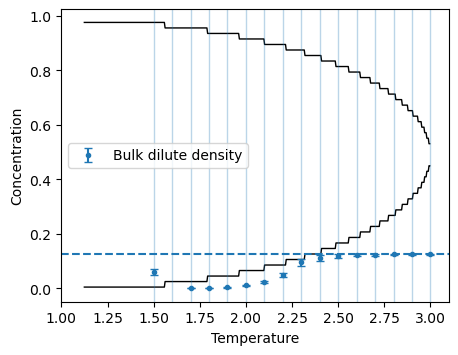

In [76]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.8))

ax.plot(Tvals, sols, color="black", lw=1)
# ax.grid(True, alpha=0.3)
ax.axhline(y=512/16**3, linestyle="dashed")
ax.set_xlabel("Temperature")
ax.set_ylabel("Concentration")

ax.set_xlim(1.0, 3.1)
for x in np.linspace(1.5, 3.0, 16):
    ax.axvline(x=x, lw = 1, alpha=0.3)

x_b = np.linspace(1.5, 3.0, 16)
x_d = np.linspace(1.5, 2.3, 8)

ax.errorbar(x_b, bdens_means, yerr=bdens_stds, fmt='o', color='C0', ecolor='C0',
            capsize=3, markersize=3, label='Bulk dilute density', zorder=10)
# ax.errorbar(x_d, ddens_means[:8], yerr=ddens_stds[:8], fmt='s', color='C1', ecolor='C1',
#             capsize=3, markersize=3, label='Droplet density (first 8)', zorder=11)

ax.legend()

In [235]:
fig.savefig("media/figures/20251126/fh_phase_diagram_with_simulations.pdf")

### Junkyard

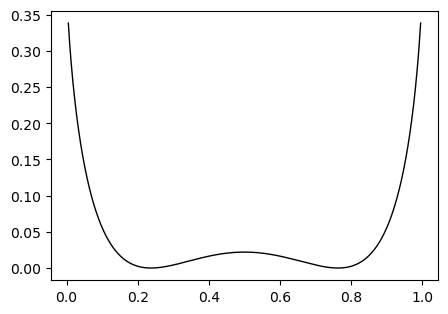

In [306]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

fs = np.abs(F_(phis) - m*phis - b)
ax.plot(phis, fs, color="black", lw=1)

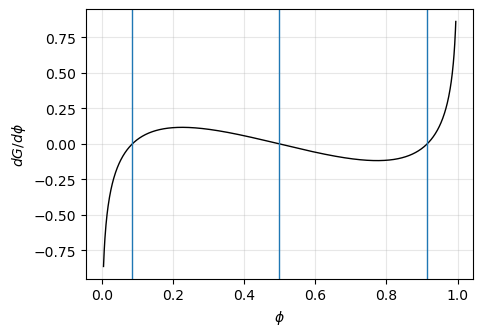

In [343]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

def G_(phi):
    return F(phi, mu, chi, T) - m*phi - b

# Numerical derivative dG/dphi using numdifftools (1D scalar argument)
dG = nd.Derivative(G_)

# Evaluate derivative pointwise on the grid of phi values and plot
dG_dphi = np.array([dG(p) for p in phis])
ax.plot(phis, dG_dphi, color="black", lw=1)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$dG/d\phi$")
ax.grid(True, alpha=0.3)

# find sign changes
zeros = np.where(dG_dphi[1:] * np.roll(dG_dphi, 1)[1:] < 0)[0]

if np.any(zeros):
    for z in zeros:
        ax.axvline(x=phis[z], lw=1)